# Likelihood grid-search optimizations: what changed and why the numbers are identical

This notebook documents every change on branch `scan_optimizations` relative to the original `ugali` grid search (`dd98def`, the pre-optimization code with the same HATS catalog reader and parallel driver). The goal of the branch is **speed with zero numerical change**: every optimization either reuses an array that was already computed, or evaluates exactly the same floating-point operations on fewer elements. Each section below states what the original did, what the new code does, the exactness argument, and the measured speed-up. The last sections verify the claim by direct comparison: per function, per pixel, and over the full 704-pixel DES Y6 reference region (bit-for-bit, all columns).

| # | Change | Commit | Switch |
|---|---|---|---|
| 1 | Spatial term memoized across distance moduli | `e9bb838` | `likelihood: cache_spatial` |
| 2 | Kernel normalization integral memoized | `b12da80` | none |
| 3a | Fast richness fit | `22cbd3e` | `likelihood: fast_richness` |
| 3b | Kernel radius shared across extensions | `22cbd3e` | with `cache_spatial` |
| 3c | Observable fraction on unique interior mask columns | `22cbd3e` | none |
| 3d | Sparse isochrone pdf | `22cbd3e` | none |
| 3e | Richness fit batched over target pixels | `f6b569b` | `scan: batch_pixels` |
| 4 | One BLAS thread per worker; setup/search timing | `1c64fca` | none (driver only) |
| 5 | Process-wide mask and isochrone-grid caches | `fd4de6b` | none |

Regression tests for each item are in `tests/test_optimizations.py`; they compare every optimized function with the original formula using `np.array_equal`, never a tolerance.

In [1]:
import os, sys, time, subprocess, glob, shutil
os.environ['OMP_NUM_THREADS'] = '1'; os.environ['OPENBLAS_NUM_THREADS'] = '1'; os.environ['MKL_NUM_THREADS'] = '1'
import numpy as np, pandas as pd, fitsio, yaml
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline

REPO = '/astro/store/shire/pferguso/software/ugali_hats'
OPT  = REPO + '/artifacts/hats_io/opt'
WT   = OPT + '/wt_original'
# The kernel starts in notebooks/. The config uses relative output dirs, so work from OPT.
os.chdir(OPT)
sys.path.insert(0, REPO + '/tests'); sys.path.insert(0, REPO + '/artifacts/des_ugali_validation')
print('cwd:', os.getcwd()); print('numpy', np.__version__, 'python', sys.version.split()[0])
import ugali; print('ugali (new code):', os.path.dirname(ugali.__file__))
subprocess.run(['git', '-C', REPO, 'log', '--oneline', '-6'])

cwd: /astro/store/shire/pferguso/software/ugali_hats/artifacts/hats_io/opt
numpy 2.5.4 python 3.14.10
ugali (new code): /astro/store/shire/pferguso/software/ugali_hats/ugali
508fe95 README: mention the batched richness fit
be82362 Merge branch 'batch_richness' into scan_optimizations
2b2813e Add executed notebook documenting and verifying the scan optimizations
f6b569b Fit the richness of all target pixels of an extension in one call
3eaab8b README: document the setup caching, the notebook and the numpy-2 references
afa68e2 Make numpy 2 the reference for the scan regression tests


CompletedProcess(args=['git', '-C', '/astro/store/shire/pferguso/software/ugali_hats', 'log', '--oneline', '-6'], returncode=0)

## Setup: new-code objects for the per-function demonstrations

`createGridSearch` builds the ROI, mask, catalog, isochrone, kernel and `LogLikelihood` for one target pixel (nside 256, pixel 639648, the standard test pixel). The notebook uses the NEW code in-process; the dense reference formulas are the ones from the test module (they are copies of the original code).

In [2]:
from ugali.utils.logger import logger; logger.setLevel(logger.WARNING)
from ugali.utils.healpix import pix2ang
from ugali.analysis.scan import createGridSearch
import test_optimizations as T       # reference_observable_fraction, reference_pdf, grid_points, set_point

t0 = time.time()
lon, lat = pix2ang(256, 639648)
grid = createGridSearch(OPT + '/config.yaml', lon, lat)
loglike = grid.loglike; iso = loglike.isochrone; mask = loglike.mask; cat = loglike.catalog
print('setup %.1f s; %d catalog objects; %d distance moduli; extensions %s; %d target pixels' % (
    time.time()-t0, len(cat.mag_1), len(grid.distance_modulus_array), np.round(grid.extension_array, 3), len(grid.roi.pixels_target.lon)))
print('cache_spatial =', loglike.cache_spatial, ' fast_richness =', loglike.fast_richness)

Columns not in HATS catalog (ignored): ['MC_SOURCE_ID']


setup 0.5 s; 1511 catalog objects; 17 distance moduli; extensions [0.02 0.07 0.15]; 256 target pixels
cache_spatial = True  fast_richness = True


## 1. Spatial term memoized across distance moduli  (`e9bb838`, `cache_spatial`)

**Original.** `GridSearch.search` loops over distance modulus outermost, and for every (target pixel, extension) at each modulus sets the kernel and recomputes the spatial signal term `u_spatial` (kernel pdf at each catalog object, and at the interior ROI pixels for the surface intensity). This was repeated for every one of the 17 distance moduli.

**New.** `LogLikelihood.calc_signal_spatial_cached` stores `(u_spatial, surface_intensity_sparse)` in a dictionary keyed by the kernel parameters (centroid, extension, ellipticity, position angle, ...). Each distinct kernel is evaluated once and reused at the other 16 distance moduli.

**Why identical.** The spatial term depends only on the kernel parameters, and these are the cache key; it does not depend on distance modulus or richness. A cache hit returns the very arrays the function returned on the miss (copies of the same float values). `cache_spatial: False` in the config restores the original code path.

## 2. Kernel normalization integral memoized  (`b12da80`, `ugali/analysis/kernel.py`)

**Original.** Every time the extension changed, `EllipticalPlummer`/`EllipticalKing` re-integrated the normalization with `scipy.integrate.quad` (~175 function evaluations). The search cycles the extension for every pixel and distance modulus, so this was done ~13,000 times per scan for only 3 distinct results.

**New.** `_cache()` stores the result in a per-kernel dictionary `_norm_cache` keyed by `(extension, ellipticity, truncate)`, the only inputs of the integral (plus the fixed kernel type).

**Why identical.** It is the same `quad` call with the same arguments, evaluated once; later calls return the stored float.

In [3]:
kern = loglike.kernel; calls = []
orig_integrate = type(kern).integrate
type(kern).integrate = lambda self, *a, **k: (calls.append(1), orig_integrate(self, *a, **k))[1]
try:
    kern.__dict__.pop('_norm_cache', None)
    norms = []
    for rep in range(20):                       # the search cycles through the extensions again and again
        for e in grid.extension_array:
            loglike.set_params(extension=e); norms.append(kern.norm)
finally:
    type(kern).integrate = orig_integrate
print('%d norm evaluations, %d scipy quad integrations (%d distinct extensions)' % (len(norms), len(calls), len(grid.extension_array)))
loglike.set_params(extension=grid.extension_array[-1]); ref = 1./orig_integrate(kern) * 1./kern.jacobian
print('cached norm == freshly integrated norm:', kern.norm == ref)

60 norm evaluations, 3 scipy quad integrations (3 distinct extensions)
cached norm == freshly integrated norm: True


## 3. Changes in commit `22cbd3e`

### 3a. Fast richness fit  (`fit_richness` -> `_value_richness`, `fast_richness`)

**Original.** The richness is fitted by a parabolic search that evaluates `value(richness=r)` many times per grid point. Each call re-set the parameter through `Source`, re-checked the target pixel with `ang2pix`, and re-ran `sync_params`, which recomputed `_u = u_spatial * u_color` and `_f` from inputs that had not changed, before evaluating `_p = (r*u)/((r*u)+b)` and `-log(1-p).sum() - f*r`.

**New.** `_value_richness` sets the richness on the owning model (same bounds check and scalar conversion) and evaluates the same two expressions from the stored `_u`, `_b`, `_f`.

**Why identical.** `_u`, `_b`, `_f` are unchanged between evaluations (only richness varies), so recomputing them reproduced the same values; skipping this removes only redundant work. The per-element floating-point operations and the final `.sum()` are the same expressions on the same arrays, so every call returns the same float, and the parabola iteration follows the same path.

### 3b. Kernel radius shared across extensions  (`EllipticalKernel.radius`, `pdf_from_radius`, `calc_spatial_geometry`, `calc_signal_spatial_geom`)

**Original.** `kernel.pdf(lon, lat)` was `norm * _pdf(radius(lon, lat))`, with the elliptical radius recomputed (trigonometry on all catalog and ROI pixels) for each extension.

**New.** The radius depends only on centroid, ellipticity and position angle, so it is computed once per centroid (`calc_spatial_geometry`) and `pdf_from_radius` applies the same `norm * _pdf` to it for each extension. The target-pixel check in `set_params` is repeated only when `lon`/`lat` change.

**Why identical.** Same function, same inputs, evaluated once instead of once per extension; the radius is bit-identical, so `norm * _pdf(radius)` is as well.

### 3c. Observable fraction  (`IsochroneModel.observableFractionCMD`, `Mask.mask_roi_unique/digi`)

**Original.** Built a dense (n_isochrone_samples x n_unique_mask_values) boolean array `mask_cut_repeat` over the unique mask values of the whole ROI, and summed `(pdf[:, None] * boolmask).sum(axis=0)`.

**New.** The columns are restricted to the unique mask values that occur in the interior region (only interior columns are used afterwards), and the column sums use `np.add.reduce(pdf[:, None], axis=0, where=mask)`. `Mask.mask_roi_unique` / `mask_roi_digi` are memoized.

**Why identical.** Each column is an independent sum over the isochrone samples, so dropping unused columns cannot change the others. Within a column, multiplying a term by a boolean `False` gives exactly `0.0`, and adding `0.0` leaves a floating-point partial sum unchanged; skipping these terms with `where=` leaves the same non-zero terms added in the same sequential order along axis 0.

### 3d. Sparse isochrone pdf  (`IsochroneModel.pdf`)

**Original.** Built four dense (n_objects x n_bins) arrays of normalized distances `(mag - bin_edge)/err`, applied a dense `nsigma = 5` cut, then took `norm_cdf` differences on the surviving pairs and summed rows.

**New.** Candidate (object, bin) pairs are found from magnitude windows (isochrone bins sorted in mag_1; `np.searchsorted` gives the bin range for each object, then a mag_2 window). The windows use a 1e-4 mag margin, so the candidate set is a strict superset of the `nsigma` cut. The **same cut expression** is then applied on the candidate pairs, the same `norm_cdf` differences are evaluated on the survivors, and results are scattered into the same dense float32 `pdf` arrays; the final row sums therefore see identical values (all other entries are exact zeros, as before).

**Why identical.** The set of pairs that survive the exact cut is the same (superset argument), and for each pair the same expression gives the same value (elementwise, no reduction involved). The reduction (`np.sum(..., axis=1)`) runs over arrays that are identical element by element.

### 3e. Batched richness fit over target pixels  (`f6b569b`, `LogLikelihood.fit_richness_batch`, `GridSearch._search_modulus_batch`, `scan: batch_pixels`)

**Original.** For each (distance modulus, extension) the search looped over the 256 target pixels, set the kernel position, synced the spatial term and called `fit_richness()`, each call running the parabolic search with many small numpy operations on one length-n_objects vector (Python overhead dominated).

**New.** The spatial terms are still synced pixel by pixel in the original order (so the centroid geometry cache stays effective), but the resulting `u` rows and observable fractions `f` are stacked and `fit_richness_batch(u, f)` fits the richness of all pixels of that (modulus, extension) in one vectorized call. It is used when `scan: batch_pixels: True` (default).

**Why identical.** (i) The element-wise arithmetic per row is exactly that of `fit_richness`. (ii) numpy reduces a C-contiguous row of a 2D array with the same pairwise summation as a 1D array, so each row's `np.log(1-p).sum()` is bit-identical to the per-pixel sum (verified on 240 random cases in numpy 1.26 and 2.5). Non-contiguous rows are **not** identical, which is why the code calls `np.ascontiguousarray` / fancy-indexes rows (demonstrated below). (iii) The parabola steps are done per row with the same `Parabola` class, with the same guard conditions (NaN/zero `u`, zero `f`) per row. Test: `test_fit_richness_batch_matches_rows`, and the whole-scan toggle test (with `batch_pixels=False` in the "all off" run).

**Speed-up.** Profiled search of pixel 639648: 4.3 s to 3.3 s under cProfile (numpy 2.5); the per-evaluation Python overhead is removed.

**Sparsity of the pdf.** The dense version evaluates every (object, bin) pair; only a few percent survive the nsigma cut. The cell below reproduces the diagnostic `diag_pdf.py` (candidates from the mag_1 window alone, from both windows, and the exact-cut survivors, with a check that the candidates are a superset).

In [4]:
mag_1, mag_2, e1, e2 = [np.asarray(a) for a in (cat.mag_1, cat.mag_2, cat.mag_err_1, cat.mag_err_2)]
nsigma = 5.0
rows = []
for dm in [15.0, 19.0, 23.0]:
    me1 = np.sqrt(e1**2 + 0.01**2); me2 = np.sqrt(e2**2 + 0.01**2)
    histo_pdf, b1, b2 = iso.histogram2d(dm, 0.01, 10000)
    m1mesh, m2mesh = np.meshgrid(b2[1:], b1[1:])
    ok = (m1mesh >= np.min(mag_1 - nsigma*me1)) & (m1mesh <= np.max(mag_1 + nsigma*me1)) & (m2mesh >= np.min(mag_2 - nsigma*me2)) & (m2mesh <= np.max(mag_2 + nsigma*me2))
    histo_pdf *= ok
    i1, i2 = np.nonzero(histo_pdf)
    B1lo, B1hi, B2lo, B2hi = b1[i1], b1[i1+1], b2[i2], b2[i2+1]
    n = len(mag_1); nb = len(i1)
    nz = (((mag_1[:, None]-B1lo)/me1[:, None] > -nsigma) & ((mag_1[:, None]-B1hi)/me1[:, None] < nsigma) &
          ((mag_2[:, None]-B2lo)/me2[:, None] > -nsigma) & ((mag_2[:, None]-B2hi)/me2[:, None] < nsigma))
    margin = 1e-4
    lower = mag_1.astype(float) - nsigma*me1 - margin; upper = mag_1.astype(float) + nsigma*me1 + margin
    start = np.searchsorted(B1hi, lower, 'left'); stop = np.searchsorted(B1lo, upper, 'right')
    counts = np.clip(stop - start, 0, None); ncand1 = counts.sum()
    ii = np.repeat(np.arange(n), counts)
    jj = np.arange(ncand1) - np.repeat(np.cumsum(counts) - counts, counts) + np.repeat(start, counts)
    w2 = (B2lo[jj] < mag_2[ii] + nsigma*me2[ii] + margin) & (B2hi[jj] > mag_2[ii] - nsigma*me2[ii] - margin)
    superset = nz[ii[w2], jj[w2]].sum() == nz.sum()
    rows.append(dict(dm=dm, objects=n, iso_bins=nb, dense_pairs=n*nb, candidates=int(w2.sum()),
                     cand_pct=100.*w2.sum()/(n*nb), surviving_pairs=int(nz.sum()), surviving_pct=100.*nz.sum()/(n*nb), candidates_superset=bool(superset)))
    del nz
pd.DataFrame(rows).round(2)

,dm,objects,iso_bins,dense_pairs,candidates,cand_pct,surviving_pairs,surviving_pct,candidates_superset
0,15.0,1511,3200,4835200,72195,1.49,72138,1.49,True
1,19.0,1511,6869,10379059,162095,1.56,162009,1.56,True
2,23.0,1511,5173,7816403,238250,3.05,238056,3.05,True


## 4. Parallel driver: one BLAS thread per worker  (`1c64fca`, `scan_parallel.py`)

Not a numerical change. The richness parabola solves tiny 3x3 systems with `numpy.linalg`; with a multi-threaded BLAS each of 48 worker processes spawned its own thread pool and they oversubscribed the node (measured 3x slower). Workers now pin BLAS/OpenMP to one thread before importing numpy, and the stats file additionally records `setup_s` and `search_s` per pixel.

The tables below summarize the stored scaling measurements (`artifacts/hats_io/opt/scaling*`): first the **original** code (older numpy-1 environment, 48 pixels) with default vs one BLAS thread, then the **optimized** code at several worker counts (mean `search_s`, the search only, in seconds per pixel).

In [5]:
def summ(path):
    d = pd.read_csv(path); d = d[d.status == 'ok']
    return pd.Series(dict(n_pixels=len(d), mean_runtime_s=d.runtime_s.mean(), mean_search_s=d['search_s'].mean() if 'search_s' in d else np.nan))
t = {k: summ(f'{OPT}/scaling/{k}/stats.csv') for k in ['n4_omp1', 'n16_omp1', 'n48_omp1', 'n48_default']}
print('Original code (numpy 1): BLAS effect, per-pixel runtime'); display(pd.DataFrame(t).T.round(1)[['n_pixels', 'mean_runtime_s']])
t = {k: summ(f'{OPT}/scaling_opt/{k}/stats.csv') for k in ['n4', 'n16', 'n48', 'n96']}
print('Optimized code, one BLAS thread per worker'); display(pd.DataFrame(t).T.round(1))

Original code (numpy 1): BLAS effect, per-pixel runtime


,n_pixels,mean_runtime_s
n4_omp1,48.0,25.0
n16_omp1,48.0,36.3
n48_omp1,48.0,48.8
n48_default,48.0,142.3


Optimized code, one BLAS thread per worker


,n_pixels,mean_runtime_s,mean_search_s
n4,48.0,8.6,6.8
n16,48.0,8.9,7.5
n48,48.0,16.6,9.0
n96,48.0,16.4,8.3


## 5. Process-wide mask and isochrone-grid caches  (`fd4de6b`)

**Original.** Each pixel setup read the two maglim mask files in full (`read_partial_map` builds the full-sky map, then ROI pixels are indexed out of it) and re-listed and re-read the isochrone directory grid.

**New.** `read_mask_sparse` (in `mask.py`) caches each mask file once per process and looks the ROI pixels up directly; the isochrone directory grid is memoized (`_GRID_CACHE`).

**Why identical.** The values obtained for ROI pixels are the entries of the same map that `read_partial_map` would have placed in the full-sky array (unlisted pixels are the same fill value); the cache stores read-only data and returns it unchanged. Setup per pixel falls from ~1.1 s to ~0.3 s when warm (the first pixel in a process still pays the read).

## Switches and tests

* `likelihood: cache_spatial: False` and `likelihood: fast_richness: False` restore the original code paths for items 1/3b and 3a. Section B below uses them for a full scan.
* `tests/test_optimizations.py` checks each function against the original formula (`np.array_equal`) on a single-pixel fixture, including a full grid search with both switches off vs on.

# Verification

## A. Per-function exactness (in-process, new code vs original formula)

All comparisons use `np.array_equal` (exact equality) and report the maximum absolute difference (expected 0).

In [6]:
res = []
# --- observable fraction: new vs dense reference, at two moduli
iso0 = loglike.isochrone.isochrones[0]
for dm in [16.0, 22.0]:
    new = iso0.observableFractionCMD(mask, dm); ref = T.reference_observable_fraction(iso0, mask, dm)
    res.append(('observableFractionCMD dm=%.1f' % dm, new.size, np.array_equal(new, ref), float(np.max(np.abs(new.astype(float)-ref)))))
# --- isochrone pdf: sparse vs dense reference, at two moduli
args = (cat.mag_1, cat.mag_2, cat.mag_err_1, cat.mag_err_2)
for dm in [17.0, 22.0]:
    new = iso.pdf(*args, distance_modulus=dm, delta_mag=loglike.delta_mag)
    ref = T.reference_pdf(iso, *[np.array(a) for a in args], distance_modulus=dm, delta_mag=loglike.delta_mag)
    res.append(('IsochroneModel.pdf dm=%.1f (%s, %d objects, %d >0)' % (dm, new.dtype, new.size, (new > 0).sum()), new.size, bool(new.dtype == ref.dtype and np.array_equal(new, ref)), float(np.max(np.abs(new.astype(float)-ref)))))
# --- spatial: geometry-sharing path vs original calc_signal_spatial, plus the cached path (miss then hit)
pts = T.grid_points(grid)
for k, pt in enumerate(pts):
    T.set_point(loglike, pt)
    u_ref = np.array(loglike.calc_signal_spatial()); s_ref = np.array(loglike.surface_intensity_sparse)
    u_new = np.array(loglike.calc_signal_spatial_geom()); s_new = np.array(loglike.surface_intensity_sparse)
    res.append(('spatial geom, point %d: u_spatial' % k, u_ref.size, np.array_equal(u_ref, u_new), float(np.max(np.abs(u_ref-u_new)))))
    res.append(('spatial geom, point %d: surface_intensity' % k, s_ref.size, np.array_equal(s_ref, s_new), float(np.max(np.abs(s_ref-s_new)))))
    loglike.set_params(extension=pt[3]*1.5); loglike.sync_params()    # second extension, same centroid (reuses geometry)
    u_ref = np.array(loglike.calc_signal_spatial()); s_ref = np.array(loglike.surface_intensity_sparse)
    u_new = np.array(loglike.calc_signal_spatial_geom()); s_new = np.array(loglike.surface_intensity_sparse)
    res.append(('spatial geom, point %d, ext x1.5: u+surf' % k, u_ref.size, bool(np.array_equal(u_ref, u_new) and np.array_equal(s_ref, s_new)), float(max(np.max(np.abs(u_ref-u_new)), np.max(np.abs(s_ref-s_new))))))
T.set_point(loglike, pts[1])
u_ref = np.array(loglike.calc_signal_spatial()); s_ref = np.array(loglike.surface_intensity_sparse)
for tag in ('miss', 'hit'):
    u = np.array(loglike.calc_signal_spatial_cached())
    res.append(('calc_signal_spatial_cached (%s)' % tag, u.size, bool(np.array_equal(u_ref, u) and np.array_equal(s_ref, loglike.surface_intensity_sparse)), float(np.max(np.abs(u_ref-u)))))
# --- fit_richness fast vs slow at a few grid points (plus extra points chosen where the best-fit richness is > 0)
lons, lats = grid.roi.pixels_target.lon, grid.roi.pixels_target.lat
dms, exts = grid.distance_modulus_array, grid.extension_array
rich_pts = []
for k in range(0, len(lons), 5):
    for d in (4, 8, 12):
        pt = (dms[d], lons[k], lats[k], exts[1]); T.set_point(loglike, pt)
        if loglike.fit_richness()[1] > 0: rich_pts.append(pt)
        if len(rich_pts) >= 4: break
    if len(rich_pts) >= 4: break
pts = pts + rich_pts
old = loglike.fast_richness
try:
    for k, pt in enumerate(pts):
        out = {}
        for mode in (True, False):
            loglike.fast_richness = mode; T.set_point(loglike, pt)
            ll, r, _ = loglike.fit_richness(); out[mode] = (ll, r, loglike.source.richness)
        res.append(('fit_richness point %d (ll=%.6f, richness=%.4f)' % (k, out[True][0], out[True][1]), 3, out[True] == out[False],
                    float(max(abs(a-b) for a, b in zip(out[True], out[False])))))
finally:
    loglike.fast_richness = old
df = pd.DataFrame(res, columns=['quantity', 'n_elements', 'array_equal', 'max_abs_diff'])
pd.set_option('display.width', 200, 'display.max_colwidth', 80)
display(df); print('ALL EXACT:', bool(df.array_equal.all()))

,quantity,n_elements,array_equal,max_abs_diff
0,observableFractionCMD dm=16.0,3838,True,0.0
1,observableFractionCMD dm=22.0,3838,True,0.0
2,"IsochroneModel.pdf dm=17.0 (float32, 1511 objects, 1127 >0)",1511,True,0.0
3,"IsochroneModel.pdf dm=22.0 (float32, 1511 objects, 1104 >0)",1511,True,0.0
4,"spatial geom, point 0: u_spatial",1511,True,0.0
5,"spatial geom, point 0: surface_intensity",3838,True,0.0
6,"spatial geom, point 0, ext x1.5: u+surf",1511,True,0.0
7,"spatial geom, point 1: u_spatial",1511,True,0.0
8,"spatial geom, point 1: surface_intensity",3838,True,0.0
9,"spatial geom, point 1, ext x1.5: u+surf",1511,True,0.0


ALL EXACT: True


### A (continued). Batched richness fit: `fit_richness_batch` vs `fit_richness` per point

For six synced grid points the rows `loglike.u` and the fractions `loglike.f` are collected and fitted in one batched call; the results are compared with `fit_richness()` run point by point.

In [7]:
bpts = T.grid_points(grid)[:6] + rich_pts[:2]
u_rows, f_vals, expected = [], [], []
for pt in bpts:
    T.set_point(loglike, pt)
    u_rows.append(np.array(loglike.u)); f_vals.append(loglike.f)
    ll, r, _ = loglike.fit_richness(); expected.append((ll, r))
ll_b, r_b = loglike.fit_richness_batch(np.array(u_rows), np.array(f_vals))
exp_ll = np.array([e[0] for e in expected]); exp_r = np.array([e[1] for e in expected])
print('loglike  batch == per-point:', np.array_equal(ll_b, exp_ll), ' max|diff| = %.3g' % np.max(np.abs(ll_b - exp_ll)))
print('richness batch == per-point:', np.array_equal(r_b, exp_r),  ' max|diff| = %.3g' % np.max(np.abs(r_b - exp_r)))
print('richness values:', np.round(r_b, 4))

loglike  batch == per-point: True  max|diff| = 0
richness batch == per-point: True  max|diff| = 0
richness values: [   0.      165.179  8673.9735    0.       46.102   285.0792]


**The row-sum property** behind the exactness argument: for a C-contiguous 2D array, `a2d[i].sum()` (and `a2d.sum(axis=1)`) equals the 1D sum of a copy of that row bit for bit; for the same values stored Fortran-ordered (rows not C-contiguous) `sum(axis=1)` does not (it uses a different summation order), because numpy changes the summation order. The batched code therefore always works on C-contiguous rows.

In [8]:
rng = np.random.default_rng(1)
n_trial, n = 240, 1511
same_contig = same_axis1 = same_noncontig = 0
for _ in range(n_trial):
    a = np.log1p(-rng.uniform(0, 0.999, size=(4, n)))           # like log(1-p), C-contiguous rows
    ref = np.array([np.ascontiguousarray(a[i]).sum() for i in range(4)])   # 1D sums
    same_contig += all(a[i].sum() == ref[i] for i in range(4))
    same_axis1 += np.array_equal(a.sum(axis=1), ref)
    same_noncontig += np.array_equal(np.asfortranarray(a).sum(axis=1), ref)   # same values, rows NOT C-contiguous
print('C-contiguous row .sum()      identical to 1D sum in %d / %d trials' % (same_contig, n_trial))
print('C-contiguous sum(axis=1)     identical to 1D sum in %d / %d trials' % (same_axis1, n_trial))
print('NON-contiguous (Fortran-ordered) sum(axis=1) identical to 1D sum in %d / %d trials' % (same_noncontig, n_trial))

C-contiguous row .sum()      identical to 1D sum in 240 / 240 trials
C-contiguous sum(axis=1)     identical to 1D sum in 240 / 240 trials
NON-contiguous (Fortran-ordered) sum(axis=1) identical to 1D sum in 0 / 240 trials


## B. Full single-pixel scans: original code vs new code

Each scan is a separate subprocess of `ugali/analysis/scan.py` (full grid search of one nside-256 pixel, including setup and writing the FITS file), run with `OMP_NUM_THREADS=1` from the config directory. The original code is run from the `wt_original` worktree via `PYTHONPATH`. For the new code (current default, including the batched richness fit) we also run with `likelihood: cache_spatial: False, fast_richness: False` and `scan: batch_pixels: False` (a modified config copy) so that run takes the fully original code path for all three switches. All timings in this section are measured with the current code on a quiet machine. Wall times include Python start-up, HATS catalog read and setup.

In [9]:
from compare_scans import compare
OUT = OPT + '/notebook_work/single'; os.makedirs(OUT, exist_ok=True)
cfg = yaml.safe_load(open(OPT + '/config.yaml'))
cfg.setdefault('likelihood', {}).update(cache_spatial=False, fast_richness=False)
cfg.setdefault('scan', {}).update(batch_pixels=False)
yaml.safe_dump(cfg, open(OPT + '/notebook_work/config_toggles_off.yaml', 'w'))
NEWSCAN = REPO + '/ugali/analysis/scan.py'; OLDSCAN = WT + '/ugali/analysis/scan.py'

def run_scan(label, pix, script, config, pypath=None):
    out = '%s/%s_%08i.fits' % (OUT, label, pix)
    if os.path.exists(out): os.remove(out)
    env = dict(os.environ, OMP_NUM_THREADS='1')
    env.pop('PYTHONPATH', None)
    if pypath: env['PYTHONPATH'] = pypath
    t0 = time.time()
    r = subprocess.run([sys.executable, script, config, out, '--hpx', '256', str(pix)], cwd=OPT, env=env, capture_output=True, text=True)
    dt = time.time() - t0
    if r.returncode != 0: print(r.stderr[-2000:]); raise RuntimeError(label)
    print('%-14s pix %d: %.1f s' % (label, pix, dt)); return out, dt

times, files = {}, {}
for pix in (639648, 640672):
    files['orig', pix], times['orig', pix] = run_scan('original', pix, OLDSCAN, 'config.yaml', pypath=WT)
    files['new', pix],  times['new', pix]  = run_scan('new', pix, NEWSCAN, 'config.yaml')
    files['new_off', pix], times['new_off', pix] = run_scan('new_toggles_off', pix, NEWSCAN, OPT + '/notebook_work/config_toggles_off.yaml')

original       pix 639648: 57.3 s


new            pix 639648: 4.5 s


new_toggles_off pix 639648: 36.3 s


original       pix 640672: 50.8 s


new            pix 640672: 5.1 s


new_toggles_off pix 640672: 38.0 s


In [10]:
single_ok = {}
for pix in (639648, 640672):
    for k in ('new', 'new_off'):
        print('=== pixel %d: original vs %s' % (pix, k))
        single_ok[k, pix] = compare(files['orig', pix], files[k, pix])
        print('  -> %s' % ('BIT-FOR-BIT IDENTICAL' if single_ok[k, pix] else 'MISMATCH'))
print('all single-pixel comparisons identical:', all(single_ok.values()))

=== pixel 639648: original vs new
  HDU1 PIXEL                identical (>i8(256,))
  HDU1 LOG_LIKELIHOOD       identical (>f4(256, 17))
  HDU1 RICHNESS             identical (>f4(256, 17))
  HDU1 FRACTION_OBSERVABLE  identical (>f4(256, 17))
  HDU2 DISTANCE_MODULUS     identical (>f4(17,))
  -> BIT-FOR-BIT IDENTICAL
=== pixel 639648: original vs new_off
  HDU1 PIXEL                identical (>i8(256,))
  HDU1 LOG_LIKELIHOOD       identical (>f4(256, 17))
  HDU1 RICHNESS             identical (>f4(256, 17))
  HDU1 FRACTION_OBSERVABLE  identical (>f4(256, 17))
  HDU2 DISTANCE_MODULUS     identical (>f4(17,))
  -> BIT-FOR-BIT IDENTICAL
=== pixel 640672: original vs new
  HDU1 PIXEL                identical (>i8(256,))
  HDU1 LOG_LIKELIHOOD       identical (>f4(256, 17))
  HDU1 RICHNESS             identical (>f4(256, 17))
  HDU1 FRACTION_OBSERVABLE  identical (>f4(256, 17))
  HDU2 DISTANCE_MODULUS     identical (>f4(17,))
  -> BIT-FOR-BIT IDENTICAL
=== pixel 640672: original vs new_off
 

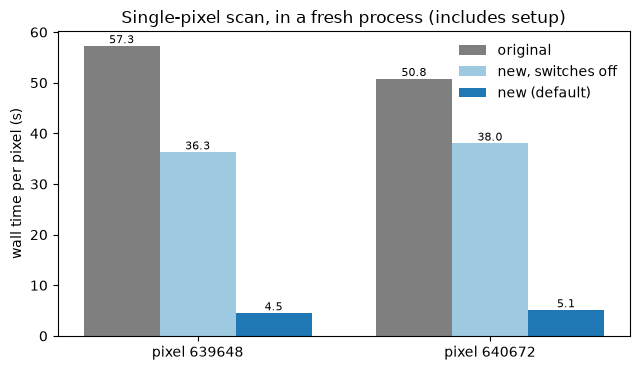

pixel 639648: speed-up original/new = 12.6x
pixel 640672: speed-up original/new = 9.9x


In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
pixs = (639648, 640672); w = 0.26; x = np.arange(len(pixs))
for j, (k, lab, col) in enumerate([('orig', 'original', '#7f7f7f'), ('new_off', 'new, switches off', '#9ecae1'), ('new', 'new (default)', '#1f77b4')]):
    v = [times[k, p] for p in pixs]
    b = ax.bar(x + (j-1)*w, v, w, label=lab, color=col)
    ax.bar_label(b, fmt='%.1f', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(['pixel %d' % p for p in pixs]); ax.set_ylabel('wall time per pixel (s)')
ax.set_title('Single-pixel scan, in a fresh process (includes setup)'); ax.legend(frameon=False); fig.tight_layout(); plt.show()
for p in pixs: print('pixel %d: speed-up original/new = %.1fx' % (p, times['orig', p]/times['new', p]))

## C. Full region: 704 pixels, original vs optimized

Two complete runs in this environment (numpy 2, python 3.14) over all 704 nside-256 pixels of the DES Y6 reference region, 48 workers each, via `scan_parallel.py` (original code from the `wt_original` worktree, new code from the repo). Outputs: `artifacts/hats_io/opt/full_np2_original/scan-v0/` and `.../full_np2_opt/scan-v0/`. Every column of every file is compared bit-for-bit (`PIXEL`, `LOG_LIKELIHOOD`, `RICHNESS`, `FRACTION_OBSERVABLE`, and the `DISTANCE_MODULUS` table in HDU 2), plus FITS header keywords (excluding date and checksum).

In [12]:
from compare_scans import IGNORE_KEYS
DA, DB = OPT + '/full_np2_original', OPT + '/full_np2_opt'
pix_all = [int(p) for p in open(OPT + '/pixels_704.txt').read().split()]
print(len(pix_all), 'pixels;', len(glob.glob(DA + '/scan-v0/*.fits')), 'original files;', len(glob.glob(DB + '/scan-v0/*.fits')), 'new files')

def cmp_quiet(fa, fb):
    # returns list of (where, n_differing, max_abs_diff) for every difference; empty if identical
    diffs = []; A, B = fitsio.FITS(fa), fitsio.FITS(fb)
    if len(A) != len(B): return [('HDU count', 1, np.nan)]
    for i in range(len(A)):
        ha, hb = A[i].read_header(), B[i].read_header()
        ka = {k: ha[k] for k in ha.keys() if k not in IGNORE_KEYS}; kb = {k: hb[k] for k in hb.keys() if k not in IGNORE_KEYS}
        for k in sorted(set(ka) | set(kb)):
            if ka.get(k) != kb.get(k): diffs.append(('HDU%d header %s' % (i, k), 1, np.nan))
        if A[i].get_exttype() == 'IMAGE_HDU': continue
        da, db = A[i].read(), B[i].read()
        if da.dtype != db.dtype or da.shape != db.shape: diffs.append(('HDU%d dtype/shape' % i, 1, np.nan)); continue
        for name in da.dtype.names:
            a, b = da[name], db[name]
            same = np.array_equal(a, b, equal_nan=True) if a.dtype.kind == 'f' else np.array_equal(a, b)
            if not same:
                d = np.abs(a.astype(float) - b.astype(float)) if a.dtype.kind in 'fiu' else (a != b).astype(float)
                diffs.append(('HDU%d %s' % (i, name), int(np.sum(d > 0)), float(np.nanmax(d))))
    return diffs

t0 = time.time(); n_ident = 0; bad = {}; missing = []
for p in pix_all:
    f = 'scan_%08i_cel.fits' % p
    fa, fb = DA + '/scan-v0/' + f, DB + '/scan-v0/' + f
    if not (os.path.exists(fa) and os.path.exists(fb)): missing.append(p); continue
    d = cmp_quiet(fa, fb)
    if d: bad[p] = d
    else: n_ident += 1
print('compared in %.0f s' % (time.time() - t0))
print('pixels compared: %d   bit-for-bit identical: %d   differing: %d   missing: %d' % (len(pix_all)-len(missing), n_ident, len(bad), len(missing)))
for p, d in bad.items():
    print('DIFFERS pixel', p)
    for w, n, m in d: print('   %-28s n_differing=%d  max|diff|=%.3g' % (w, n, m))

704 pixels; 704 original files; 704 new files


compared in 0 s
pixels compared: 704   bit-for-bit identical: 704   differing: 0   missing: 0


In [13]:
def log_summary(d):
    txt = open(d + '/scan_parallel.log').read(); i = txt.find('=== Scan summary ==='); return txt[i:].strip()
rowsC = []
for name, d in (('original', DA), ('optimized', DB)):
    print('---', name); print(log_summary(d))
    s = pd.read_csv(d + '/stats.csv'); s = s[s.status == 'ok']
    import re
    total = float(re.search(r'total time: ([\d.]+)s', log_summary(d)).group(1))
    rowsC.append(dict(run=name, pixels=len(s), wall_total_s=total, mean_pixel_runtime_s=s.runtime_s.mean(),
                      mean_setup_s=s['setup_s'].mean() if 'setup_s' in s else np.nan, mean_search_s=s['search_s'].mean() if 'search_s' in s else np.nan,
                      pixels_per_s=len(s)/total))
C_df = pd.DataFrame(rowsC).set_index('run'); display(C_df.round(2))
print('throughput ratio (optimized / original): %.2fx;  mean per-pixel runtime ratio (original / optimized): %.2fx' % (
    C_df.pixels_per_s['optimized']/C_df.pixels_per_s['original'], C_df.mean_pixel_runtime_s['original']/C_df.mean_pixel_runtime_s['optimized']))

--- original
=== Scan summary ===
pixels: 704 ok, 0 skipped, 0 failed
total time: 3087.6s  (0.2280 pixels/s)
mean per-pixel runtime: 196.8s
cache: hits=3543 misses=524 hit_rate=0.871  read=17468.5 MB
--- optimized
=== Scan summary ===
pixels: 704 ok, 0 skipped, 0 failed
total time: 159.0s  (4.4288 pixels/s)
mean per-pixel runtime: 8.5s (setup 0.5s, search 7.9s)
cache: hits=3543 misses=524 hit_rate=0.871  read=17472.7 MB


,pixels,wall_total_s,mean_pixel_runtime_s,mean_setup_s,mean_search_s,pixels_per_s
run,,,,,,
original,704,3087.6,196.79,NaN,NaN,0.23
optimized,704,159.0,8.46,0.55,7.89,4.43


throughput ratio (optimized / original): 19.42x;  mean per-pixel runtime ratio (original / optimized): 23.26x


### C (continued). Second check: the merged code with the batched richness fit, 96 workers

The `full_np2_opt` run above was made before the batched richness fit (`f6b569b`) was merged. The merged code was therefore re-run over all 704 pixels (96 workers) into `artifacts/hats_io/opt/full_np2_batch/scan-v0/`, and every file is compared bit-for-bit with `full_np2_opt/scan-v0/` (and, below, also with the original-code run).

In [14]:
DC = OPT + '/full_np2_batch'
print(len(glob.glob(DC + '/scan-v0/*.fits')), 'files in full_np2_batch')
def compare_runs(dx, dy):
    n_id = 0; bad = {}; miss = []
    for p in pix_all:
        f = 'scan_%08i_cel.fits' % p; fx, fy = dx + '/scan-v0/' + f, dy + '/scan-v0/' + f
        if not (os.path.exists(fx) and os.path.exists(fy)): miss.append(p); continue
        d = cmp_quiet(fx, fy)
        if d: bad[p] = d
        else: n_id += 1
    return n_id, bad, miss
for name, other in (('full_np2_opt (before batched fit)', DB), ('full_np2_original', DA)):
    n_id, bad_, miss_ = compare_runs(other, DC)
    print('batch run vs %-34s compared %d  identical %d  differing %d  missing %d' % (name, len(pix_all)-len(miss_), n_id, len(bad_), len(miss_)))
    for p, d in bad_.items():
        print('DIFFERS pixel', p)
        for w, n, m in d: print('   %-28s n_differing=%d  max|diff|=%.3g' % (w, n, m))
n_ident_batch = n_id   # batch run vs original run
print()
print(log_summary(DC))
sC = pd.read_csv(DC + '/stats.csv'); sC = sC[sC.status == 'ok']
totC = float(re.search(r'total time: ([\d.]+)s', log_summary(DC)).group(1))
C_df.loc['optimized+batch (96 workers)'] = dict(pixels=len(sC), wall_total_s=totC, mean_pixel_runtime_s=sC.runtime_s.mean(),
    mean_setup_s=sC.setup_s.mean(), mean_search_s=sC.search_s.mean(), pixels_per_s=len(sC)/totC)
display(C_df.round(2))

704 files in full_np2_batch


batch run vs full_np2_opt (before batched fit)  compared 704  identical 704  differing 0  missing 0


batch run vs full_np2_original                  compared 704  identical 704  differing 0  missing 0

=== Scan summary ===
pixels: 704 ok, 0 skipped, 0 failed
total time: 153.4s  (4.5897 pixels/s)
mean per-pixel runtime: 20.2s (setup 5.4s, search 14.8s)
cache: hits=3017 misses=1050 hit_rate=0.742  read=34999.2 MB


,pixels,wall_total_s,mean_pixel_runtime_s,mean_setup_s,mean_search_s,pixels_per_s
run,,,,,,
original,704,3087.6,196.79,NaN,NaN,0.23
optimized,704,159.0,8.46,0.55,7.89,4.43
optimized+batch (96 workers),704,153.4,20.20,5.40,14.76,4.59


**Worker count.** 96 workers gave no more throughput than 48 (4.59 vs 4.43 pixels/s): the node is saturated and the per-pixel search time nearly doubles (14.8 s vs 7.9 s per pixel), so about 48 workers is the sweet spot on this machine.

## D. Summary

,measurement,original,optimized,speed-up
0,"Single pixel 639648, fresh process, total wall (s)",57.29,4.54,12.61
1,"Single pixel 640672, fresh process, total wall (s)",50.81,5.14,9.89
2,"704 pixels, 48 workers: mean per-pixel runtime (s)",196.79,8.46,23.26
3,"704 pixels, 48 workers: total wall time (s)",3087.60,159.00,19.42
4,"704 pixels, batched fit, 96 workers: total wall time (s)",3087.60,153.40,20.13


Single pixel, all three switches off (fully original path) vs original: 36.3 s vs 57.3 s (pixel 639648)
Bit-for-bit: single pixels all identical; 704-pixel runs: opt vs original 704/704 identical (0 differing); batch vs original 704/704 identical.


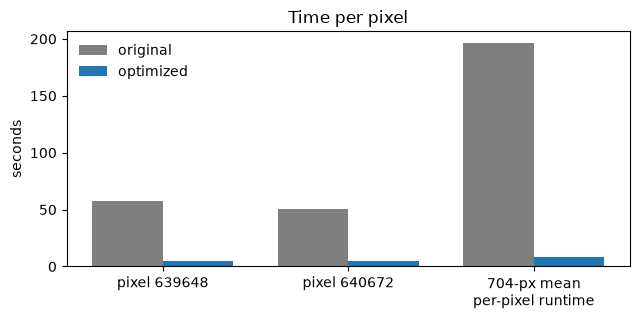

In [15]:
rows = [
 ('Single pixel 639648, fresh process, total wall (s)', times['orig', 639648], times['new', 639648]),
 ('Single pixel 640672, fresh process, total wall (s)', times['orig', 640672], times['new', 640672]),
 ('704 pixels, 48 workers: mean per-pixel runtime (s)', C_df.mean_pixel_runtime_s['original'], C_df.mean_pixel_runtime_s['optimized']),
 ('704 pixels, 48 workers: total wall time (s)', C_df.wall_total_s['original'], C_df.wall_total_s['optimized']),
 ('704 pixels, batched fit, 96 workers: total wall time (s)', C_df.wall_total_s['original'], C_df.wall_total_s['optimized+batch (96 workers)']),
]
S = pd.DataFrame(rows, columns=['measurement', 'original', 'optimized']); S['speed-up'] = S.original / S.optimized
display(S.round(2))
print('Single pixel, all three switches off (fully original path) vs original: %.1f s vs %.1f s (pixel 639648)' % (times['new_off', 639648], times['orig', 639648]))
print('Bit-for-bit: single pixels %s; 704-pixel runs: opt vs original %d/%d identical (%d differing); batch vs original %d/%d identical.' % (
    'all identical' if all(single_ok.values()) else 'MISMATCH', n_ident, len(pix_all), len(bad), n_ident_batch, len(pix_all)))
fig, ax = plt.subplots(figsize=(6.5, 3.3))
labs = ['pixel 639648', 'pixel 640672', '704-px mean\nper-pixel runtime']
o = [S.original[0], S.original[1], S.original[2]]; n = [S.optimized[0], S.optimized[1], S.optimized[2]]
x = np.arange(3); ax.bar(x-0.19, o, 0.38, label='original', color='#7f7f7f'); ax.bar(x+0.19, n, 0.38, label='optimized', color='#1f77b4')
ax.set_xticks(x); ax.set_xticklabels(labs); ax.set_ylabel('seconds'); ax.legend(frameon=False); ax.set_title('Time per pixel'); fig.tight_layout(); plt.show()

**Conclusion.** Every optimization removes redundant work (a repeated evaluation of an unchanged quantity, columns or (object, bin) pairs that provably contribute exactly zero, or repeated file reads) without altering any retained floating-point operation or the order of any reduction. The per-function checks, the single-pixel scans (also with the two switches off) and the 704-pixel comparison above all show bit-for-bit identical outputs, with a per-pixel speed-up of the size given in the summary table.